# Étape 5 – Machine Learning : prédire les avis négatifs

**Objectif métier :** repérer **à l'avance** les commandes qui risquent de recevoir un avis négatif (1 ou 2 étoiles),
pour que le service client puisse agir (prévenir le client, accélérer l'envoi, offrir un geste commercial…).

**Type de problème :** c'est une **classification binaire** — le modèle doit répondre *oui* (avis négatif) ou *non*.

**Le principe du Machine Learning supervisé :**
1. on montre au modèle des milliers de commandes **dont on connaît déjà la réponse** (la note) → c'est l'**entraînement** ;
2. le modèle apprend tout seul les liens entre les caractéristiques de la commande et la note ;
3. on vérifie ensuite s'il devine juste sur des commandes **qu'il n'a jamais vues** → c'est le **test**.

> 💡 Vocabulaire : les caractéristiques (délai, prix, distance…) s'appellent les **features** ;
> ce qu'on veut prédire (avis négatif oui/non) s'appelle la **cible** (*target*).

## 0. Préparation

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import create_engine

sys.path.insert(0, str(Path.cwd().parent / "src"))
from config import pg_url

engine = create_engine(pg_url())
COULEUR = "#2a78d6"
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

## 1. Construire le jeu de données : une ligne par commande

On rassemble en **une seule requête SQL** tout ce qu'on sait sur chaque commande livrée :
prix, frais de port, poids et volume des produits, catégorie, États du client et du vendeur,
coordonnées GPS, moyen de paiement, délais… et bien sûr la note.

*(La requête est longue mais tu connais déjà toutes les briques : CTE, `JOIN`, `GROUP BY`, `LEFT JOIN`.
Deux nouveautés : `DISTINCT ON` garde une seule ligne par commande — l'article le plus cher —
et `ARRAY_AGG(...)[1]` récupère le moyen de paiement du plus gros paiement.)*

In [2]:
REQUETE = """
    WITH notes AS (
        SELECT order_id, AVG(review_score) AS note
        FROM order_reviews
        GROUP BY order_id
    ),
    articles AS (
        SELECT i.order_id,
               COUNT(*)                                                         AS nb_articles,
               COUNT(DISTINCT i.seller_id)                                      AS nb_vendeurs,
               SUM(i.price)                                                     AS prix_total,
               SUM(i.freight_value)                                             AS frais_port,
               SUM(p.product_weight_g)                                          AS poids_total_g,
               SUM(p.product_length_cm * p.product_height_cm * p.product_width_cm) AS volume_total_cm3
        FROM order_items i
        JOIN products p ON p.product_id = i.product_id
        GROUP BY i.order_id
    ),
    article_principal AS (           -- l'article le plus cher de la commande
        SELECT DISTINCT ON (i.order_id)
               i.order_id, i.seller_id,
               COALESCE(t.product_category_name_english, 'inconnue') AS categorie
        FROM order_items i
        JOIN products p ON p.product_id = i.product_id
        LEFT JOIN category_translation t ON t.product_category_name = p.product_category_name
        ORDER BY i.order_id, i.price DESC
    ),
    paiements AS (
        SELECT order_id,
               MAX(payment_installments)                                AS nb_echeances,
               (ARRAY_AGG(payment_type ORDER BY payment_value DESC))[1] AS moyen_paiement
        FROM order_payments
        GROUP BY order_id
    )
    SELECT o.order_id,
           EXTRACT(MONTH FROM o.order_purchase_timestamp)::int                            AS mois_achat,
           o.order_estimated_delivery_date::date - o.order_purchase_timestamp::date       AS delai_promis_jours,
           a.nb_articles, a.nb_vendeurs, a.prix_total, a.frais_port,
           a.poids_total_g, a.volume_total_cm3,
           ap.categorie,
           c.customer_state AS etat_client,
           s.seller_state   AS etat_vendeur,
           gc.lat AS lat_client,  gc.lng AS lng_client,
           gs.lat AS lat_vendeur, gs.lng AS lng_vendeur,
           pm.moyen_paiement, pm.nb_echeances,
           o.order_delivered_customer_date::date - o.order_purchase_timestamp::date      AS delai_jours,
           o.order_delivered_customer_date::date - o.order_estimated_delivery_date::date AS ecart_jours,
           n.note
    FROM orders o
    JOIN notes             n  ON n.order_id  = o.order_id
    JOIN articles          a  ON a.order_id  = o.order_id
    JOIN article_principal ap ON ap.order_id = o.order_id
    JOIN customers         c  ON c.customer_id = o.customer_id
    JOIN sellers           s  ON s.seller_id   = ap.seller_id
    LEFT JOIN geolocation_zip gc ON gc.zip_code_prefix = c.customer_zip_code_prefix
    LEFT JOIN geolocation_zip gs ON gs.zip_code_prefix = s.seller_zip_code_prefix
    LEFT JOIN paiements       pm ON pm.order_id = o.order_id
    WHERE o.order_status = 'delivered'
      AND o.order_delivered_customer_date IS NOT NULL
"""

df = pd.read_sql(REQUETE, engine)
print(f"{len(df):,} commandes x {df.shape[1]} colonnes".replace(",", " "))
df.head()

95 824 commandes x 21 colonnes


,order_id,mois_achat,delai_promis_jours,nb_articles,nb_vendeurs,prix_total,frais_port,poids_total_g,volume_total_cm3,categorie,...,etat_vendeur,lat_client,lng_client,lat_vendeur,lng_vendeur,moyen_paiement,nb_echeances,delai_jours,ecart_jours,note
0,00018f77f2f0320c557190d7a144bdd3,4,19,1,1,239.90,19.93,30000.0,60000.0,pet_shop,...,SP,-20.205187,-50.927017,-23.565803,-46.519192,credit_card,3.0,16,-3,4.0
1,00010242fe8c5a6d1ba2dd792cb16214,9,16,1,1,58.90,13.29,650.0,3528.0,cool_stuff,...,SP,-21.763009,-41.310799,-22.499217,-44.125997,credit_card,2.0,7,-9,5.0
2,00024acbcdf0a6daa1e931b038114c75,8,12,1,1,12.99,12.79,200.0,2400.0,perfumery,...,SP,-23.106036,-46.592481,-20.554801,-47.387749,credit_card,2.0,6,-6,4.0
3,00048cc3ae777c65dbb7d2a0634bc1ea,5,22,1,1,21.90,12.69,450.0,2880.0,housewares,...,SP,-19.740232,-47.925038,-21.189678,-47.787260,boleto,1.0,7,-15,4.0
4,0005f50442cb953dcd1d21e1fb923495,7,21,1,1,53.99,11.40,850.0,1827.0,books_technical,...,SP,-23.556739,-46.899006,-23.467609,-46.586825,credit_card,1.0,2,-19,4.0


## 2. Créer de nouvelles features (« feature engineering »)

Les données brutes ne suffisent pas toujours : on **fabrique** des variables plus parlantes pour le modèle.
- **`distance_km`** : distance à vol d'oiseau entre le client et le vendeur (formule de **haversine**, qui tient compte de la courbure de la Terre)
- **`meme_etat`** : le vendeur est-il dans le même État que le client ? (1 = oui, 0 = non)
- **`avis_negatif`** : notre **cible** → 1 si la note est ≤ 2, sinon 0

In [3]:
def haversine_km(lat1, lng1, lat2, lng2):
    """Distance en km entre deux points GPS."""
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine_km(df["lat_client"], df["lng_client"], df["lat_vendeur"], df["lng_vendeur"])
df["meme_etat"] = (df["etat_client"] == df["etat_vendeur"]).astype(int)
df["avis_negatif"] = (df["note"] <= 2).astype(int)

df[["distance_km", "meme_etat", "avis_negatif"]].describe().round(2)

,distance_km,meme_etat,avis_negatif
count,95348.00,95824.00,95824.00
mean,600.09,0.36,0.13
std,592.01,0.48,0.33
min,0.00,0.00,0.00
25%,184.96,0.00,0.00
50%,433.77,0.00,0.00
75%,798.23,1.00,0.00
max,3398.55,1.00,1.00


## 3. La cible est-elle équilibrée ?

In [4]:
repartition = df["avis_negatif"].value_counts(normalize=True).mul(100).round(1)
repartition.index = ["Avis positif / neutre (0)", "Avis négatif (1)"]
repartition

Avis positif / neutre (0)    87.2
Avis négatif (1)             12.8
Name: proportion, dtype: float64

➡️ Les classes sont **déséquilibrées** : il y a beaucoup plus de clients contents que de mécontents.
On verra que c'est un **piège** pour évaluer un modèle.

## 4. ⚠️ La fuite de données (« data leakage »)

C'est **l'erreur n°1** en Machine Learning, et une question classique d'entretien.

Imagine qu'on donne au modèle `ecart_jours` (le retard réel). Il deviendrait très bon… mais c'est de la **triche** :
**au moment où l'on veut prédire** (juste après l'achat), le colis n'est pas encore livré, on **ne connaît pas encore** le retard !
Un modèle qui utilise une information du futur paraît excellent en test… et ne sert à rien en vrai.

On construit donc **deux scénarios** :

| Scénario | Quand prédit-on ? | Features autorisées |
|---|---|---|
| **A – À l'achat** | juste après la commande | tout ce qu'on sait à l'achat (prix, distance, délai promis…) |
| **B – À la livraison** | quand le colis arrive, **avant** que le client note | A + le délai réel et le retard |

Le scénario B est utile aussi : le service client peut contacter le client **entre la livraison et l'avis**.

In [5]:
FEATURES_NUM_ACHAT = ["delai_promis_jours", "nb_articles", "nb_vendeurs", "prix_total", "frais_port",
                      "poids_total_g", "volume_total_cm3", "distance_km", "meme_etat",
                      "nb_echeances", "mois_achat"]
FEATURES_CAT = ["categorie", "etat_client", "moyen_paiement"]
FEATURES_LIVRAISON = ["delai_jours", "ecart_jours"]

FEATURES_A = FEATURES_NUM_ACHAT + FEATURES_CAT                       # scénario A
FEATURES_B = FEATURES_NUM_ACHAT + FEATURES_LIVRAISON + FEATURES_CAT  # scénario B

print(f"Scénario A : {len(FEATURES_A)} features")
print(f"Scénario B : {len(FEATURES_B)} features")

Scénario A : 14 features
Scénario B : 16 features


## 5. Séparer entraînement et test

On coupe les données en deux :
- **80 % pour l'entraînement** : le modèle apprend sur ces commandes ;
- **20 % pour le test** : on les cache au modèle, puis on vérifie ses prédictions dessus.

C'est comme un examen : si on donnait à l'élève les questions de l'examen pendant ses révisions,
sa note ne mesurerait pas ce qu'il a vraiment compris.

`stratify=y` garde **la même proportion d'avis négatifs** dans les deux parties.
`random_state=42` rend le découpage **reproductible** (même résultat à chaque exécution).

In [6]:
from sklearn.model_selection import train_test_split

X = df[FEATURES_B]          # on garde toutes les colonnes ; chaque modèle choisira les siennes
y = df["avis_negatif"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Entraînement : {len(X_train):,} commandes".replace(",", " "))
print(f"Test         : {len(X_test):,} commandes".replace(",", " "))
print(f"% d'avis négatifs : train {100 * y_train.mean():.1f} % | test {100 * y_test.mean():.1f} %")

Entraînement : 76 659 commandes
Test         : 19 165 commandes
% d'avis négatifs : train 12.8 % | test 12.8 %


## 6. Le modèle « bête » de référence (baseline)

Avant de construire un vrai modèle, on se demande : **quel score obtiendrait un modèle qui ne réfléchit pas ?**

Le plus simple : répondre **toujours « avis positif »**. On mesure deux choses :
- **Accuracy (exactitude)** : % de prédictions correctes, toutes classes confondues ;
- **Rappel (recall) des avis négatifs** : parmi les **vrais** avis négatifs, combien le modèle en a-t-il **détectés** ?

In [7]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

print(f"Accuracy                   : {100 * accuracy_score(y_test, pred):.1f} %")
print(f"Rappel des avis négatifs   : {100 * recall_score(y_test, pred):.1f} %")

Accuracy                   : 87.2 %
Rappel des avis négatifs   : 0.0 %


### 🎯 À toi d'interpréter

1. L'accuracy du modèle « bête » est-elle **bonne ou mauvaise** à première vue ? Pourquoi est-elle si élevée ?
2. Que vaut son **rappel** ? Ce modèle est-il **utile** pour le service client ?
3. Si un collègue t'annonce fièrement « mon modèle a 85 % d'accuracy ! », que lui réponds-tu ?
4. Pour chacune de ces features, dis si elle est autorisée dans le **scénario A** (à l'achat) : `frais_port`, `ecart_jours`, `distance_km`, `note`.

✍️ *Écris tes réponses ici :*

1. 87,2 % : élevée mais trompeuse. Le modèle répond toujours "positif" et 87,2 % des commandes le sont : l'accuracy reflète seulement le déséquilibre des classes.
2. Rappel = 0 % : il ne détecte aucun client mécontent, donc il est inutile pour le service client.
3. 85 % d'accuracy, c'est moins bien que le modèle bête (87,2 %). Sur des classes déséquilibrées, il faut regarder le rappel et la précision, et toujours comparer à une baseline.
4. frais_port : oui. distance_km : oui. ecart_jours : non (connu seulement après la livraison = fuite de données). note : non (c'est la cible).

# Partie 2 – Les vrais modèles

## 7. Préparer les données pour le modèle : le *pipeline*

Un modèle ne comprend que des **nombres**, sans **valeurs manquantes**. Il faut donc préparer les données :
- **Valeurs manquantes** (`SimpleImputer`) : ex. `distance_km` est vide quand un code postal n'a pas de coordonnées → on la remplace par la **médiane** ;
- **Mise à l'échelle** (`StandardScaler`) : `prix_total` va jusqu'à 13 000 alors que `meme_etat` vaut 0 ou 1 → on ramène tout à la même échelle, sinon certains modèles donnent trop de poids aux grands nombres ;
- **Encodage des catégories** (`OneHotEncoder`) : la colonne `etat_client` = « SP », « RJ »… devient une colonne 0/1 par État.
  Les catégories rares (< 100 commandes) sont regroupées dans « autres ».

Un **`Pipeline`** enchaîne la préparation **et** le modèle en un seul objet.
Gros avantage : la préparation est **apprise uniquement sur le train**, puis appliquée au test → pas de fuite de données.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def construire_pipeline(features, modele):
    """Préparation des données + modèle, enchaînés dans un seul objet."""
    num = [f for f in features if f not in FEATURES_CAT]
    cat = [f for f in features if f in FEATURES_CAT]
    preparation = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), cat),
    ])
    return Pipeline([("preparation", preparation), ("modele", modele)])

## 8. Comment juger un modèle : la matrice de confusion

Pour chaque commande du test, le modèle prédit « positif » ou « négatif ». On compare à la réalité :

| | **Prédit : positif** | **Prédit : négatif** |
|---|---|---|
| **Réel : positif** | ✅ Vrai négatif — client content, laissé tranquille | ⚠️ **Fausse alerte** — on contacte un client content pour rien |
| **Réel : négatif** | ❌ **Raté** — client mécontent non détecté | ✅ **Bonne détection** — client mécontent repéré à temps |

À partir de là, on calcule :
- **Rappel** = bonnes détections ÷ tous les vrais mécontents → *« quelle part des mécontents attrape-t-on ? »*
- **Précision** = bonnes détections ÷ toutes les alertes → *« quand le modèle alerte, a-t-il raison ? »*
- **F1** = compromis entre rappel et précision (moyenne harmonique)
- **ROC-AUC** = capacité à **classer** les commandes de la moins risquée à la plus risquée : **0,5 = hasard**, **1 = parfait**

💼 **Le choix dépend du métier** : si contacter un client coûte peu (un e-mail), on préfère un **bon rappel** quitte à avoir des fausses alertes.
Si chaque contact coûte cher (un geste commercial), on veut une **bonne précision**.

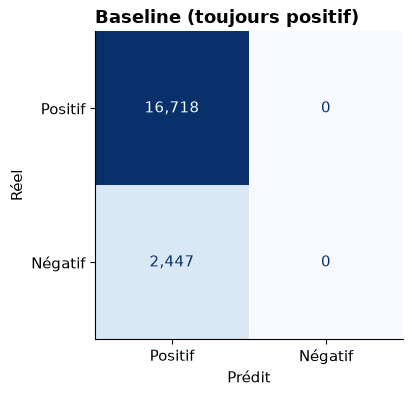

accuracy     0.872
précision    0.000
rappel       0.000
F1           0.000
ROC-AUC      0.500
dtype: float64

In [9]:
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score)

RESULTATS = []

def evaluer(nom, modele, features):
    """Entraîne le modèle, affiche sa matrice de confusion et enregistre ses scores."""
    pipeline = construire_pipeline(features, modele)
    pipeline.fit(X_train[features], y_train)
    pred = pipeline.predict(X_test[features])
    proba = pipeline.predict_proba(X_test[features])[:, 1]

    scores = {"modèle": nom,
              "accuracy": accuracy_score(y_test, pred),
              "précision": precision_score(y_test, pred, zero_division=0),
              "rappel": recall_score(y_test, pred),
              "F1": f1_score(y_test, pred),
              "ROC-AUC": roc_auc_score(y_test, proba)}
    RESULTATS.append(scores)

    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Positif", "Négatif"],
        cmap="Blues", colorbar=False, values_format=",", ax=ax)
    ax.set_title(nom, loc="left", fontweight="bold")
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    plt.show()
    return pipeline, pd.Series(scores).drop("modèle").astype(float).round(3)

# On ajoute la baseline au tableau de comparaison
_, scores = evaluer("Baseline (toujours positif)", DummyClassifier(strategy="most_frequent"), FEATURES_A)
scores

## 9. Modèle 1 : la régression logistique

Malgré son nom, c'est un modèle de **classification**. Il donne un **poids** à chaque feature
(ex. « +1 jour de délai promis → risque un peu plus élevé ») et additionne ces poids pour calculer une **probabilité** d'avis négatif.
Simple, rapide, et **interprétable** : c'est le premier modèle à essayer.

⚖️ **`class_weight="balanced"`** : comme les mécontents ne sont que 12,8 %, le modèle aurait tendance à les ignorer
(comme la baseline !). Cette option leur donne **plus de poids** pendant l'apprentissage : rater un mécontent « coûte » plus cher.

**Scénario A – à l'achat :**

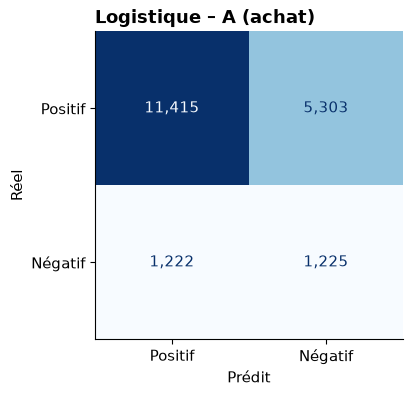

accuracy     0.660
précision    0.188
rappel       0.501
F1           0.273
ROC-AUC      0.630
dtype: float64

In [10]:
from sklearn.linear_model import LogisticRegression

logreg_A, scores = evaluer("Logistique – A (achat)",
                           LogisticRegression(class_weight="balanced", max_iter=1000), FEATURES_A)
scores

## 10. Modèle 2 : l'arbre de décision

Un arbre pose une **suite de questions oui/non**, comme un jeu de « Qui est-ce ? » :
*« Le délai promis dépasse-t-il 25 jours ? → Oui → Le client est-il dans un autre État ? → … »*

`max_depth=6` limite l'arbre à 6 questions d'affilée : sans limite, il apprendrait **par cœur** les commandes d'entraînement
(c'est le **surapprentissage**, ou *overfitting*) et se tromperait sur les nouvelles.
`min_samples_leaf=50` impose au moins 50 commandes par décision finale, pour la même raison.

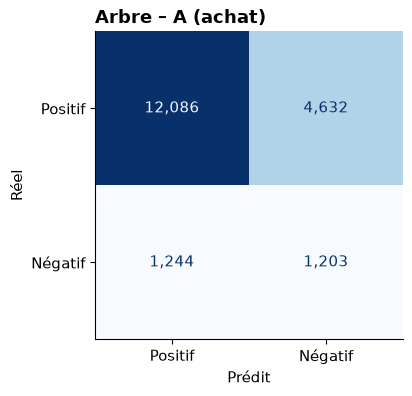

accuracy     0.693
précision    0.206
rappel       0.492
F1           0.291
ROC-AUC      0.637
dtype: float64

In [11]:
from sklearn.tree import DecisionTreeClassifier

arbre_A, scores = evaluer("Arbre – A (achat)",
                          DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                                 class_weight="balanced", random_state=42),
                          FEATURES_A)
scores

## 11. Scénario B : à la livraison (on ajoute le délai réel et le retard)

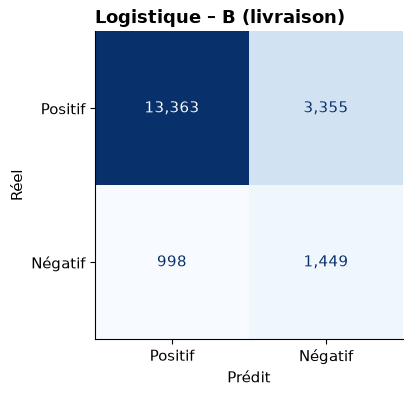

accuracy     0.773
précision    0.302
rappel       0.592
F1           0.400
ROC-AUC      0.747
dtype: float64

In [12]:
logreg_B, scores = evaluer("Logistique – B (livraison)",
                           LogisticRegression(class_weight="balanced", max_iter=1000), FEATURES_B)
scores

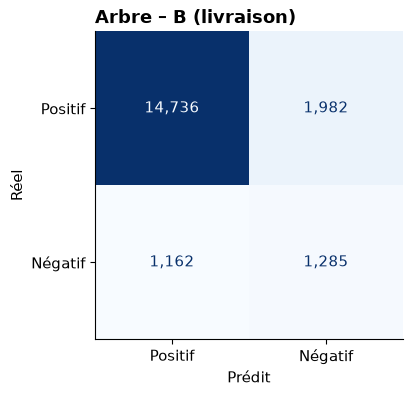

accuracy     0.836
précision    0.393
rappel       0.525
F1           0.450
ROC-AUC      0.748
dtype: float64

In [13]:
arbre_B, scores = evaluer("Arbre – B (livraison)",
                          DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                                 class_weight="balanced", random_state=42),
                          FEATURES_B)
scores

## 12. Tableau comparatif

In [14]:
comparaison = pd.DataFrame(RESULTATS).set_index("modèle").round(3)
comparaison

,accuracy,précision,rappel,F1,ROC-AUC
modèle,,,,,
Baseline (toujours positif),0.872,0.000,0.000,0.000,0.500
Logistique – A (achat),0.660,0.188,0.501,0.273,0.630
Arbre – A (achat),0.693,0.206,0.492,0.291,0.637
Logistique – B (livraison),0.773,0.302,0.592,0.400,0.747
Arbre – B (livraison),0.836,0.393,0.525,0.450,0.748


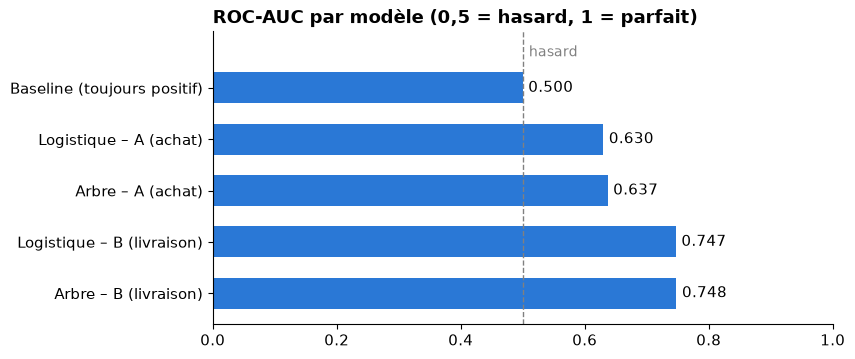

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.8))
barres = ax.barh(comparaison.index[::-1], comparaison["ROC-AUC"][::-1], color=COULEUR, height=0.6)
ax.bar_label(barres, labels=[f"{v:.3f}" for v in comparaison["ROC-AUC"][::-1]], padding=4)
ax.axvline(0.5, color="gray", linestyle="--", linewidth=1)
ax.text(0.51, len(comparaison) - 0.45, "hasard", color="gray", fontsize=10, va="bottom")
ax.set_ylim(-0.6, len(comparaison) + 0.1)
ax.set_xlim(0, 1)
ax.set_title("ROC-AUC par modèle (0,5 = hasard, 1 = parfait)", loc="left", fontweight="bold")
plt.show()

### 🎯 À toi d'interpréter

1. Avec `class_weight="balanced"`, l'**accuracy** de la régression logistique A est-elle meilleure ou moins bonne que la baseline ? Est-ce grave ? Regarde son **rappel**.
2. Dans la matrice de confusion « Logistique – A » : combien de **mécontents détectés** ? Combien de **fausses alertes** ?
3. Compare la **ROC-AUC** du scénario A et du scénario B. Pourquoi un tel écart ?
4. Le scénario A (à l'achat) est-il **inutile** pour autant ? (Compare à 0,5.)
5. 💼 Tu es responsable du service client : quel modèle déploies-tu, et **à quel moment** contactes-tu le client ?

✍️ *Écris tes réponses ici :*

1. L'accuracy est moins bonne que la baseline (65,8 % contre 87,2 %), et ce n'est pas grave : c'est même bon signe. Le rappel passe de 0 % à 52 %, donc le modèle détecte enfin un client mécontent sur deux. La baseline avait une bonne accuracy uniquement parce qu'elle répondait toujours "content".

2. 1 273 clients mécontents détectés (sur 2 447) et 5 373 fausses alertes. Rappel = 52 %, précision = 19 % : quand le modèle alerte, il a raison environ 1 fois sur 5.

3. ROC-AUC de 0,635 pour le scénario A contre 0,756 pour le scénario B. L'écart vient de l'information sur la livraison réelle, en particulier le retard par rapport à la date promise, qui est le facteur le plus important dans le mécontentement (il multiplie les avis négatifs par 7).

4. Le scénario A n'est pas inutile : avec 0,635, il fait mieux que le hasard (0,5). Cela montre que d'autres facteurs que la livraison jouent sur le mécontentement (distance, catégorie, nombre d'articles…). Surtout, il permet d'agir avant que le problème arrive.

5. Je combine les deux modèles, chacun à son moment :
- juste après l'achat : modèle A, pour la prévention (expédier en priorité les commandes à risque, annoncer une date prudente) ;
- dès que la date promise est dépassée : prévenir le client et lui donner une nouvelle date ;
- à la livraison, avant l'avis : modèle B (l'arbre, ROC-AUC 0,756), pour contacter les clients à risque avec un message ou un geste commercial.

# Partie 3 – Améliorer les modèles et comprendre ce qui compte

## 13. La forêt aléatoire (*random forest*) : la sagesse des foules 🌳🌳🌳

Un seul arbre de décision est fragile : il dépend beaucoup des commandes qu'il a vues.
Une **forêt aléatoire** entraîne **des centaines d'arbres**, chacun sur un échantillon un peu différent des données
et avec un sous-ensemble des features, puis les fait **voter**. Les erreurs des uns sont compensées par les autres.

C'est comme demander l'avis à 150 personnes plutôt qu'à une seule : la moyenne est plus fiable.

⏳ *Cette cellule prend environ 1 minute.*

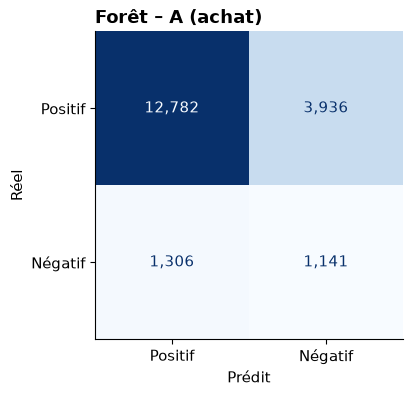

accuracy     0.726
précision    0.225
rappel       0.466
F1           0.303
ROC-AUC      0.655
dtype: float64


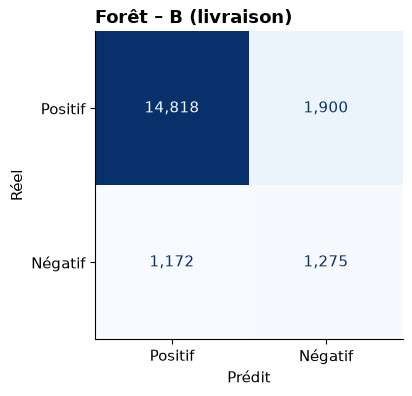

accuracy     0.840
précision    0.402
rappel       0.521
F1           0.454
ROC-AUC      0.760
dtype: float64

In [16]:
from sklearn.ensemble import RandomForestClassifier

def foret():
    return RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=20,
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=42)

foret_A, scores = evaluer("Forêt – A (achat)", foret(), FEATURES_A)
print(scores)
foret_B, scores = evaluer("Forêt – B (livraison)", foret(), FEATURES_B)
scores

> 💡 **Et KNN ou SVM ?** Ce sont aussi des modèles de classification classiques.
> Mais avec 76 000 commandes, le **SVM** devient extrêmement lent (son temps de calcul explose avec le nombre de lignes),
> et le **KNN** doit comparer chaque nouvelle commande à toutes les commandes d'entraînement.
> Savoir **écarter un modèle pour une raison concrète** fait partie du métier.

## 14. La validation croisée : le bon score n'était-il qu'un coup de chance ?

Jusqu'ici, on a testé chaque modèle sur **un seul** découpage train / test. Et si ce découpage était particulièrement favorable ?

La **validation croisée à 5 plis** (*5-fold cross-validation*) découpe le train en 5 parts :
le modèle s'entraîne sur 4 parts et se teste sur la 5ᵉ, **5 fois de suite** en changeant la part de test.
On obtient **5 scores** : leur **moyenne** est plus fiable, et leur **écart-type** dit si le modèle est **stable**.

⏳ *Environ 1 à 2 minutes.*

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nom, modele, features in [
    ("Logistique – B", LogisticRegression(class_weight="balanced", max_iter=1000), FEATURES_B),
    ("Forêt – B",      foret(),                                                    FEATURES_B),
]:
    scores_cv = cross_val_score(construire_pipeline(features, modele),
                                X_train[features], y_train, cv=plis, scoring="roc_auc", n_jobs=-1)
    print(f"{nom:<16} ROC-AUC par pli : {np.round(scores_cv, 3)}")
    print(f"{'':<16} moyenne = {scores_cv.mean():.3f}  ± {scores_cv.std():.3f}\n")

Logistique – B   ROC-AUC par pli : [0.742 0.75  0.75  0.738 0.738]
                 moyenne = 0.744  ± 0.005

Forêt – B        ROC-AUC par pli : [0.762 0.762 0.764 0.752 0.755]
                 moyenne = 0.759  ± 0.005



## 15. Optimiser les hyperparamètres : trouver les meilleurs réglages

Les **hyperparamètres** sont les **réglages** qu'on choisit **avant** l'entraînement
(ex. `max_depth` = profondeur de l'arbre). Jusqu'ici, on les a fixés « au jugé ».

`GridSearchCV` essaie **toutes les combinaisons** d'une grille de valeurs, évalue chacune par validation croisée,
et garde la meilleure. On le fait ici sur l'arbre de décision (rapide à entraîner) :
5 profondeurs × 3 tailles de feuille = 15 combinaisons × 3 plis = **45 entraînements**.

In [18]:
from sklearn.model_selection import GridSearchCV

grille = {
    "modele__max_depth":        [4, 6, 8, 10, 12],
    "modele__min_samples_leaf": [20, 50, 100],
}
recherche = GridSearchCV(
    construire_pipeline(FEATURES_B, DecisionTreeClassifier(class_weight="balanced", random_state=42)),
    grille, cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    scoring="roc_auc", n_jobs=-1)
recherche.fit(X_train[FEATURES_B], y_train)

print("Meilleurs réglages :", recherche.best_params_)
print(f"ROC-AUC moyenne en validation croisée : {recherche.best_score_:.3f}")

# Tableau des 15 combinaisons, de la meilleure à la moins bonne
(pd.DataFrame(recherche.cv_results_)
   [["param_modele__max_depth", "param_modele__min_samples_leaf", "mean_test_score"]]
   .rename(columns={"param_modele__max_depth": "max_depth",
                    "param_modele__min_samples_leaf": "min_samples_leaf",
                    "mean_test_score": "ROC-AUC moyenne"})
   .sort_values("ROC-AUC moyenne", ascending=False)
   .round(3).head(8))

Meilleurs réglages : {'modele__max_depth': 6, 'modele__min_samples_leaf': 100}
ROC-AUC moyenne en validation croisée : 0.747


,max_depth,min_samples_leaf,ROC-AUC moyenne
5,6,100,0.747
4,6,50,0.746
8,8,100,0.746
3,6,20,0.745
7,8,50,0.744
6,8,20,0.742
11,10,100,0.742
10,10,50,0.740


On évalue l'arbre optimisé sur le **test** (qu'il n'a jamais vu, même pendant la recherche) :

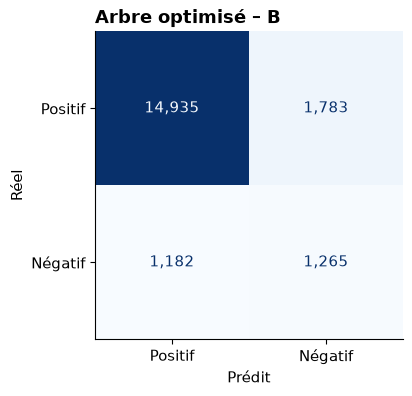

accuracy     0.845
précision    0.415
rappel       0.517
F1           0.460
ROC-AUC      0.747
dtype: float64

In [19]:
meilleurs = {k.replace("modele__", ""): v for k, v in recherche.best_params_.items()}
arbre_opt_B, scores = evaluer("Arbre optimisé – B",
                              DecisionTreeClassifier(class_weight="balanced", random_state=42, **meilleurs),
                              FEATURES_B)
scores

In [20]:
comparaison = pd.DataFrame(RESULTATS).set_index("modèle").round(3)
comparaison.sort_values("ROC-AUC", ascending=False)

,accuracy,précision,rappel,F1,ROC-AUC
modèle,,,,,
Forêt – B (livraison),0.840,0.402,0.521,0.454,0.760
Arbre – B (livraison),0.836,0.393,0.525,0.450,0.748
Logistique – B (livraison),0.773,0.302,0.592,0.400,0.747
Arbre optimisé – B,0.845,0.415,0.517,0.460,0.747
Forêt – A (achat),0.726,0.225,0.466,0.303,0.655
Arbre – A (achat),0.693,0.206,0.492,0.291,0.637
Logistique – A (achat),0.660,0.188,0.501,0.273,0.630
Baseline (toujours positif),0.872,0.000,0.000,0.000,0.500


## 16. Qu'est-ce qui compte vraiment ? L'importance des features

Un modèle performant, c'est bien. **Comprendre pourquoi** il prédit, c'est ce qui intéresse le manager.

On utilise l'**importance par permutation** : on **mélange au hasard** une colonne (ex. `distance_km`)
et on regarde **de combien la ROC-AUC chute**. Si elle chute beaucoup, c'est que le modèle avait besoin de cette information.
Si elle ne bouge pas, la feature ne servait à rien.

⏳ *Environ 1 minute (calcul sur 5 000 commandes du test pour aller plus vite).*

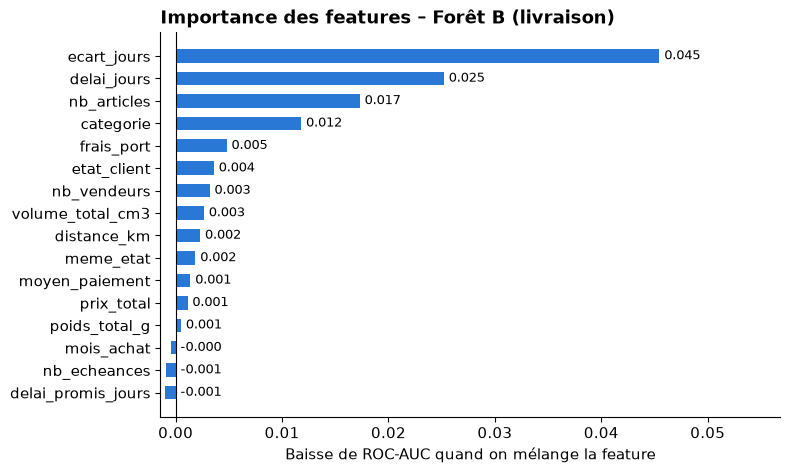

ecart_jours           0.0455
delai_jours           0.0252
nb_articles           0.0173
categorie             0.0118
frais_port            0.0048
etat_client           0.0036
nb_vendeurs           0.0032
volume_total_cm3      0.0027
distance_km           0.0023
meme_etat             0.0019
moyen_paiement        0.0014
prix_total            0.0011
poids_total_g         0.0005
mois_achat           -0.0005
nb_echeances         -0.0009
delai_promis_jours   -0.0010
dtype: float64

In [21]:
from sklearn.inspection import permutation_importance

echantillon = X_test.sample(min(5000, len(X_test)), random_state=42)
y_echantillon = y_test.loc[echantillon.index]

def importances(modele, features, titre):
    res = permutation_importance(modele, echantillon[features], y_echantillon,
                                 scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=-1)
    imp = pd.Series(res.importances_mean, index=features).sort_values()
    fig, ax = plt.subplots(figsize=(8, 5))
    barres = ax.barh(imp.index, imp.values, color=COULEUR, height=0.6)
    decalage = imp.max() * 0.01
    for y, v in enumerate(imp.values):      # valeur toujours écrite à droite de la barre
        ax.text(max(v, 0) + decalage, y, f"{v:.3f}", va="center", fontsize=9)
    ax.set_xlim(min(imp.min() * 1.5, -imp.max() * 0.02), imp.max() * 1.25)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(titre, loc="left", fontweight="bold")
    ax.set_xlabel("Baisse de ROC-AUC quand on mélange la feature")
    plt.show()
    return imp.sort_values(ascending=False).round(4)

importances(foret_B, FEATURES_B, "Importance des features – Forêt B (livraison)")

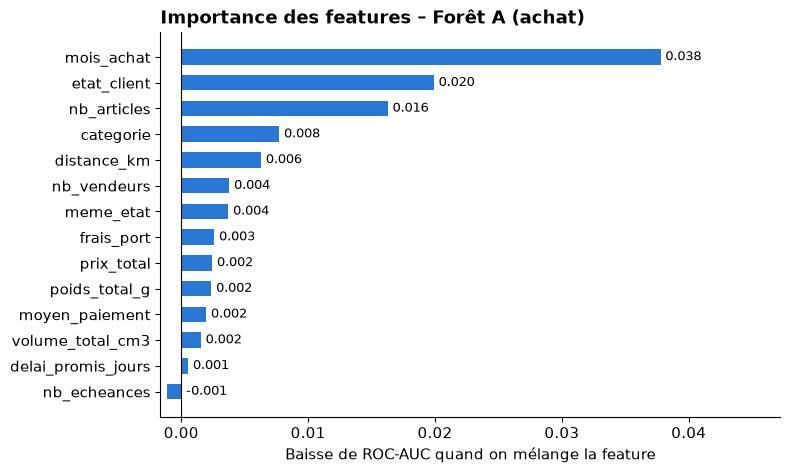

mois_achat            0.0378
etat_client           0.0199
nb_articles           0.0163
categorie             0.0077
distance_km           0.0063
nb_vendeurs           0.0038
meme_etat             0.0037
frais_port            0.0026
prix_total            0.0024
poids_total_g         0.0024
moyen_paiement        0.0020
volume_total_cm3      0.0015
delai_promis_jours    0.0005
nb_echeances         -0.0011
dtype: float64

In [22]:
importances(foret_A, FEATURES_A, "Importance des features – Forêt A (achat)")

### 🎯 À toi d'interpréter

1. La **forêt aléatoire** fait-elle mieux que l'arbre seul et la logistique ? De combien (ROC-AUC) ?
2. Validation croisée : l'**écart-type** est-il petit ou grand ? Que peut-on en conclure sur la **fiabilité** du score ?
3. Quels sont les **meilleurs réglages** trouvés par `GridSearchCV` ? L'arbre optimisé gagne-t-il beaucoup ?
4. Scénario B : quelle est la feature **la plus importante**, et de loin ? Cohérent avec l'étape 4 ?
5. Scénario A : quelles sont les **3 features** les plus importantes **au moment de l'achat** ?
6. 💼 Si tu présentais ce projet à un recruteur : quel modèle retiens-tu au final, et quelle est ta **phrase de conclusion** ?

✍️ *Écris tes réponses ici :*

1. Oui mais de peu : la forêt atteint 0,655 (A) et 0,760 (B) de ROC-AUC, contre 0,630-0,637 et 0,747-0,748 pour la logistique et l'arbre. Trois modèles différents plafonnent au même niveau : la limite vient des données, pas du modèle.
2. Écart-type de ± 0,005 : très petit, le modèle est stable. La moyenne en validation croisée (0,759) est quasi identique au score test (0,760) : pas de coup de chance, pas de surapprentissage.
3. max_depth = 6 et min_samples_leaf = 100. Gain nul (0,747 contre 0,748) : les gros gains viennent des features, pas des réglages. Les arbres plus profonds font moins bien (surapprentissage).
4. ecart_jours (le retard), loin devant (0,046), puis delai_jours (0,025). Cohérent avec l'étape 4 : le retard multiplie les avis négatifs par 7.
5. mois_achat, etat_client, nb_articles. Attention : mois_achat capte probablement des crises logistiques passées (ex. après le Black Friday 2017) plutôt qu'une règle générale. Il faudrait valider le modèle sur une période future (train 2017, test 2018).
6. Modèle retenu : forêt aléatoire, version A à l'achat (prévention) et version B à la livraison (rattrapage, détecte 1 mécontent sur 2). Conclusion : le facteur n°1 est le retard par rapport à la date promise ; il faut promettre des dates prudentes et contacter en priorité les clients livrés en retard.
conclusion : 
J’ai construit un modèle qui détecte un client mécontent sur deux dès la livraison, avant qu’il laisse son avis (ROC-AUC 0,76, stable en validation croisée). Le facteur n°1 est le retard par rapport à la date promise, ce qui confirme mes analyses statistiques. Ma recommandation : promettre des dates prudentes et contacter en priorité les clients livrés en retard.